In [2]:
import sqlite3
import pandas as pd

# Create a database in memory
conn = sqlite3.connect(":memory:")

# Create our KL Field learning dataset
data = {
    "Sample":["A", "B", "C", "D", "E"],
    "Porosity": [8, 12, 20, 24, 36],
    "prosity_Class": ["Low", "Low", "High", "High", "High"]
}
df = pd.DataFrame(data)

# Send the DataFrame to the SQL database
df.to_sql("WellSamples", conn, index=False, if_exists="replace")

print("SQL database table created successfully!")

SQL database table created successfully!


In [4]:
pd.read_sql_query(
    "SELECT * FROM WellSamples;",
    conn
)

,Sample,Porosity,prosity_Class
0,A,8,Low
1,B,12,Low
2,C,20,High
3,D,24,High
4,E,36,High


In [5]:
pd.read_sql_query("""
   SELECT *
   FROM WellSamples
   WHERE Porosity >= 20
   ORDER BY Porosity DESC;
""", conn)

,Sample,Porosity,prosity_Class
0,E,36,High
1,D,24,High
2,C,20,High


In [7]:
pd.read_sql_query("""
   SELECT *
   FROM WellSamples
   WHERE Porosity >= 20
   ORDER BY Porosity DESC
   LIMIT 2;
""", conn)

,Sample,Porosity,prosity_Class
0,E,36,High
1,D,24,High


In [8]:
pd.read_sql_query("""
    SELECT COUNT(*) AS Total_Samples
    FROM WellSamples;
""", conn)

,Total_Samples
0,5


In [10]:
pd.read_sql_query("""
    SELECT AVG(Porosity) AS Average_Porosity
    FROM WellSamples;
""", conn)

,Average_Porosity
0,20.0


In [11]:
pd.read_sql_query("""
   SELECT
     prosity_Class,
     COUNT(*) AS Sample_Count,
     AVG(Porosity) AS Average_Porosity,
     MIN(Porosity) AS Minimum_Porosity,
     MAX(Porosity) AS Maximum_Porosity
   FROM WellSamples
   GROUP BY prosity_Class;
""", conn)

,prosity_Class,Sample_Count,Average_Porosity,Minimum_Porosity,Maximum_Porosity
0,High,3,26.666667,20,36
1,Low,2,10.000000,8,12


In [12]:
pd.read_sql_query("""
    SELECT SUM(Porosity) AS Total_Porosity
    FROM WellSamples;
""", conn)

,Total_Porosity
0,100


In [15]:
pd.read_sql_query("""
   SELECT MAX(Porosity) AS Highest_Porosity
   FROM WellSamples;
""", conn)

,Highest_Porosity
0,36


In [16]:
pd.read_sql_query("""
    SElECT
        prosity_Class,
        AVG(Porosity) AS Average_Porosity
    FROM WellSamples
    GROUP BY prosity_Class
    HAVING AVG(Porosity) >15;
""", conn)

,prosity_Class,Average_Porosity
0,High,26.666667


In [20]:
pd.read_sql_query("""
    SELECT prosity_Class, COUNT(*) AS Sample_Count
    FROM WellSamples
    GROUP BY prosity_Class
    HAVING COUNT(*) >= 3;
""", conn)

,prosity_Class,Sample_Count
0,High,3


In [22]:
sample_details = pd.DataFrame({
    "Sample": ["A", "B", "C", "D", "E"],
    "Location": ["North", "North", "South", "South", "East"]
})
sample_details.to_sql(
    "SampleDetails",
    conn,
    index=False,
    if_exists="replace"
)

print("SampleDetails table created!")

SampleDetails table created!


In [23]:
pd.read_sql_query("""
   SELECT
       w.Sample,
       w.Porosity,
       w.prosity_Class,
       d.Location
    FROM WellSamples AS w
    INNER JOIN SampleDetails As d
        ON w.Sample = d.Sample;
""", conn)

,Sample,Porosity,prosity_Class,Location
0,A,8,Low,North
1,B,12,Low,North
2,C,20,High,South
3,D,24,High,South
4,E,36,High,East


In [26]:
pd.read_sql_query("""
   SELECT
      w.Sample,
      w.Porosity,
      d.Location
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
        ON w.Sample = d.Sample;
""", conn)

,Sample,Porosity,Location
0,A,8,North
1,B,12,North
2,C,20,South
3,D,24,South
4,E,36,East


In [29]:
pd.DataFrame({
    "Sample":["F"],
    "Porosity":[18],
    "prosity_Class":["Low"]
}).to_sql(
        "WellSample",
         conn,
         index=False,
         if_exists="append"
)

1

In [31]:
pd.read_sql_query("""
    SELECT
       w.Sample,
       w.Porosity,
       d.Location
    FROM WellSamples AS w
    LEFT JOIN SampleDatails AS d
       ON w.Sample = d.Sample;
""", conn)

DatabaseError: Execution failed on sql '
    SELECT
       w.Sample,
       w.Porosity,
       d.Location
    FROM WellSamples AS w
    LEFT JOIN SampleDatails AS d
       ON w.Sample = d.Sample;
': no such table: SampleDatails

In [32]:
pd.read_sql_query("""
    SELECT
        w.Sample,
        w.Porosity,
        d.Location
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
        ON w.Sample = d.Sample;
""", conn)

,Sample,Porosity,Location
0,A,8,North
1,B,12,North
2,C,20,South
3,D,24,South
4,E,36,East


In [1]:
pd.read_sql_query("""
    SELECT *
    FROM Wellsamples
    ORDER BY Sample;
""", conn)

NameError: name 'pd' is not defined

In [3]:
import pandas as pd
import sqlite3

In [4]:
print(conn)

NameError: name 'conn' is not defined

In [5]:
import pandas as pd
import sqlite3

conn = sqlite3.connect(":memory:")

print("Database connection created successfully!")

Database connection created successfully!


In [7]:
data = {
    "Sample": ["A", "B", "C", "D", "E", "F"],
    "Porosity": [8, 12, 20, 24, 36, 18],
    "prosity_Class":[
        "Low", "Low", "High", "High", "High", "Low"
    ]
}
df = pd.DataFrame(data)

df.to_sql(
    "WellSamples",
    conn,
    index=False,
    if_exists="replace"
)
df

,Sample,Porosity,prosity_Class
0,A,8,Low
1,B,12,Low
2,C,20,High
3,D,24,High
4,E,36,High
5,F,18,Low


In [10]:
sample_details = pd.DataFrame({
    "Sample": ["A", "B", "C", "D", "E"],
    "Location":["North", "North", "South", "South", "East"]
})
sample_details.to_sql(
    "SampleDetails",
    conn,
    index=False,
    
    if_exists="replace"
)
sample_details

,Sample,Location
0,A,North
1,B,North
2,C,South
3,D,South
4,E,East


In [11]:
pd.read_sql_query("""
   SELECT
      w.Sample,
      w.Porosity,
      w.prosity_Class,
      d.Location
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
      ON w.Sample = d.Sample
    ORDER BY w.Sample;
""", conn)

,Sample,Porosity,prosity_Class,Location
0,A,8,Low,North
1,B,12,Low,North
2,C,20,High,South
3,D,24,High,South
4,E,36,High,East
5,F,18,Low,NaN


In [14]:
pd.read_sql_query("""
    SELECT
       w.Sample,
       w.Porosity,
       w.prosity_Class
    FROM Wellsamples AS w
    LEFT JOIN SampleDetails AS d
         ON w.Sample = d.Sample
        WHERE d.Location IS NULL;
""", conn)

,Sample,Porosity,prosity_Class
0,F,18,Low


In [13]:
pd.read_sql_query("""
    SELECT
        w.Sample,
        w.Porosity,
        w.prosity_Class
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
        ON w.Sample = d.Sample
    WHERE d.Location IS NULL;
""", conn)

,Sample,Porosity,prosity_Class
0,F,18,Low


In [15]:
pd.read_sql_query("""
    SELECT
       d.Location,
       COUNT(w.Sample) AS Number_of_Samples
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
      ON w.Sample = d.Sample
    GROUP BY d.Location
    ORDER BY Number_of_Samples DESC;
""", conn)

,Location,Number_of_Samples
0,South,2
1,North,2
2,East,1
3,NaN,1


In [16]:
pd.read_sql_query("""
    SELECT
        d.Location,
        COUNT(w.Sample) AS Number_of_Samples,
        ROUND(AVG(w.Porosity), 2) AS Average_Porosity
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
       ON w.Sample = d.Sample
    GROUP BY d.Location
    ORDER BY Average_Porosity DESC;
""", conn)

,Location,Number_of_Samples,Average_Porosity
0,East,1,36.0
1,South,2,22.0
2,NaN,1,18.0
3,North,2,10.0


In [17]:
pd.read_sql_query("""
   SELECT
      d.Location,
      COUNT(w.Sample) AS Number_of_Samples,
      ROUND(AVG(w.Porosity),2) AS Average_Porosity
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
        ON w.Sample = d.Sample
    GROUP BY d.Location
    HAVING AVG(w.Porosity) > 15
    ORDER BY Average_Porosity DESC;
""", conn)

,Location,Number_of_Samples,Average_Porosity
0,East,1,36.0
1,South,2,22.0
2,NaN,1,18.0


In [19]:
pd.read_sql_query("""
    SELECT
       w.Sample,
       w.Porosity,
       d.Location
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
       ON w.Sample = d.Sample
    WHERE w.Porosity > 15
    ORDER BY w.Porosity DESC;
""", conn)

,Sample,Porosity,Location
0,E,36,East
1,D,24,South
2,C,20,South
3,F,18,NaN


In [20]:
pd.read_sql_query("""
   SELECT
       d.Location,
       COUNT(w.Sample) AS Number_of_Samples,
       ROUND(AVG(w.Porosity), 2) AS Average_porosity
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
         ON w.Sample = d.Sample
    WHERE w.Porosity > 15
    GROUP BY d.Location
    HAVING COUNT(w.Sample) >= 1
    ORDER BY Average_Porosity DESC;
""", conn)
    

,Location,Number_of_Samples,Average_porosity
0,East,1,36.0
1,South,2,22.0
2,NaN,1,18.0


In [23]:
pd.read_sql_query("""
   SELECT
      w.Sample,
      w.Porosity,
      w.prosity_Class,
      d.Location
    FROM WellSamples AS w
    LEFT JOIN SampleDetails AS d
       ON w.Sample = d.Sample
    ORDER BY w.Porosity DESC
    LIMIT 1;
""", conn)

,Sample,Porosity,prosity_Class,Location
0,E,36,High,East


In [25]:
pd.read_sql_query("""
    SELECT
        Sample,
        Porosity,
        prosity_Class,
        RANK() OVER (ORDER BY Porosity DESC) AS Porosity_Rank
    FROM WellSamples;
""", conn)

,Sample,Porosity,prosity_Class,Porosity_Rank
0,E,36,High,1
1,D,24,High,2
2,C,20,High,3
3,F,18,Low,4
4,B,12,Low,5
5,A,8,Low,6


In [26]:
pd.read_sql_query("""
   SELECT
       Sample,
       Porosity,
       ROUND(
           AVG(Porosity) OVER (
                ORDER BY Porosity DESC
                ROWS BETWEEN UNBOUNDED PRECEDING
                AND CURRENT ROW
            ),2
        ) AS Running_Average
    FROM WellSamples
    ORDER BY Porosity DESC;
""", conn)

,Sample,Porosity,Running_Average
0,E,36,36.00
1,D,24,30.00
2,C,20,26.67
3,F,18,24.50
4,B,12,22.00
5,A,8,19.67


In [27]:
pd.read_sql_query("""
   SELECT
       Sample,
       Porosity,
       ROUND(AVG(Porosity) OVER (), 2) AS Overall_Average,
       ROUND(Porosity - AVG(Porosity) OVER (), 2)
          AS Difference_From_Average
    FROM WellSamples
    ORDER BY Porosity DESC;
""", conn)

,Sample,Porosity,Overall_Average,Difference_From_Average
0,E,36,19.67,16.33
1,D,24,19.67,4.33
2,C,20,19.67,0.33
3,F,18,19.67,-1.67
4,B,12,19.67,-7.67
5,A,8,19.67,-11.67


In [29]:
pd.read_sql_query("""
        SELECT
            Sample,
            Porosity,
            ROUND(AVG(Porosity) OVER (), 2) AS Overall_Average,
            ROUND(
                (Porosity - AVG(Porosity) OVER ())
                / AVG(Porosity) OVER () * 100,
                2
            ) AS Percentage_Difference
        FROM WellSamples
        ORDER BY Porosity DESC;
""", conn)

,Sample,Porosity,Overall_Average,Percentage_Difference
0,E,36,19.67,83.05
1,D,24,19.67,22.03
2,C,20,19.67,1.69
3,F,18,19.67,-8.47
4,B,12,19.67,-38.98
5,A,8,19.67,-59.32


In [30]:
pd.read_sql_query("""
   SELECT
       Sample,
       Porosity,
       CASE
           WHEN Porosity < 15 THEN 'Low'
           WHEN Porosity > 25 THEN 'Medium'
           ELSE 'High'
        END AS Porosity_Category
    FROM WellSamples
    ORDER BY Porosity DESC;
""", conn)

,Sample,Porosity,Porosity_Category
0,E,36,Medium
1,D,24,High
2,C,20,High
3,F,18,High
4,B,12,Low
5,A,8,Low


In [32]:
pd.read_sql_query("""
    SELECT
         CASE
             WHEN Porosity < 15 THEN 'Low'
             WHEN Porosity < 25 THEN 'Medium'
             ELSE 'High'
         
     END AS Porosity_Category,
     COUNT(*) AS Number_of_Samples,
     ROUND(AVG(Porosity), 2) AS Average_Porosity
  FROM WellSamples
  GROUP BY Porosity_Category
  ORDER BY Average_Porosity;
""", conn)

,Porosity_Category,Number_of_Samples,Average_Porosity
0,Low,2,10.00
1,Medium,3,20.67
2,High,1,36.00


In [33]:
pd.read_sql_query("""
 
   SELECT
   Porosity_Category,
   Number_of_Samples,
   ROUND(
     Number_of_Samples * 100.0/
     SUM(Number_of_Samples) OVER(),
     2
    )AS Percentage_of_Samples
  FROM (
    SELECT
       CASE
           WHEN Porosity < 15 THEN 'Low'
           WHEN Porosity < 25 THEN 'Mediun'
           ELSE 'High'
        END
    )
    ORDER BY Percentage_of_Samples DESC;
""", conn)
  

DatabaseError: Execution failed on sql '
   SELECT
   Porosity_Category,
   Number_of_Samples,
   ROUND(
     Number_of_Samples * 100.0/
     SUM(Number_of_Samples) OVER(),
     2
    )AS Percentage_of_Samples
  FROM (
    SELECT
       CASE
           WHEN Porosity < 15 THEN 'Low'
           WHEN Porosity < 25 THEN 'Mediun'
           ELSE 'High'
        END
    )
    ORDER BY Percentage_of_Samples DESC;
': no such column: Porosity

In [34]:
pd.read_sql_query("""
    WITH CategoryCounts AS (
        SELECT
            CASE
                WHEN Porosity < 15 THEN 'Low'
                WHEN Porosity < 25 THEN 'Medium'
                ELSE 'High'
            END AS Porosity_Category,
            COUNT(*) AS Number_of_Samples
        FROM WellSamples
        GROUP BY
            CASE
                WHEN Porosity < 15 THEN 'Low'
                WHEN Porosity < 25 THEN 'Medium'
                ELSE 'High'
            END
    )
    SELECT
        Porosity_Category,
        Number_of_Samples,
        ROUND(
            Number_of_Samples * 100.0 /
            SUM(Number_of_Samples) OVER (),
            2
        ) AS Percentage_of_Samples
    FROM CategoryCounts
    ORDER BY Percentage_of_Samples DESC;
""", conn)

,Porosity_Category,Number_of_Samples,Percentage_of_Samples
0,Medium,3,50.00
1,Low,2,33.33
2,High,1,16.67


In [38]:
pd.read_sql_query("""
   WITH CategorizedSamples AS (
       SELECT
           Sample,
           Porosity,
           CASE
               WHEN Porosity < 15 THEN 'Low'
               WHEN Porosity < 25 THEN 'Medium'
               ELSE 'High'
            END AS Porosity_Category
        FROM WellSamples
    )
    SELECT
         Porosity_Category,
         COUNT(*) AS Number_of_Samples,
         MAX(Porosity) AS Maximum_Porosity,
         MIN(Porosity) AS Minimum_Porosity
    FROM CategorizedSamples
    GROUP BY Porosity_Category
    ORDER BY Maximum_Porosity DESC;
""", conn)
   

,Porosity_Category,Number_of_Samples,Maximum_Porosity,Minimum_Porosity
0,High,1,36,36
1,Medium,3,24,18
2,Low,2,12,8


In [39]:
pd.read_sql_query("""
   WITH CategorizedSamples As (
     SELECT 
           Sample,
           Porosity,
           CASE
               WHEN Porosity < 15 THEN 'Low'
               WHEN Porosity < 25 THEN 'Medium'
               ELSE 'High'
            END AS Porosity_Category
        FROM WellSamples
    ),
    RankedSamples AS (
         SELECT
               Sample,
               Porosity,
               Porosity_Category,
               ROW_NUMBER() OVER (
                  PARTITION BY Porosity_Category
                  ORDER BY Porosity DESC
            ) AS Row_Number
        FROM CategorizedSamples
    )
    SELECT
        Porosity_Category,
        Sample,
        Porosity
    FROM RankedSamples
    WHERE Row_Number = 1
    ORDER BY Porosity DESC;
""", conn)

,Porosity_Category,Sample,Porosity
0,High,E,36
1,Medium,D,24
2,Low,B,12


In [41]:
pd.read_sql_query("""
    WITH CategorizedSamples AS (
        SELECT
              Sample,
              Porosity,
              CASE
                  WHEN Porosity < 15 THEN 'Low'
                  WHEN Porosity < 25 THEN 'Medium'
                  ELSE 'High'
             END AS Porosity_Category
        FRom WellSamples
    )
    SELECT
         Sample,
         Porosity_Category,
         Porosity,
         ROUND(
            AVG(Porosity) OVER (
                PARTITION BY Porosity_Category
            ), 2
        ) AS Category_Average,
        ROUND(
            Porosity - AVG(Porosity) OVER (
                 PARTITION BY Porosity_Category
            ), 2
        ) AS Difference_From_Category_Average
    FROM CategorizedSamples
    ORDER BY Porosity_Category, Porosity DESC;
""", conn)

,Sample,Porosity_Category,Porosity,Category_Average,Difference_From_Category_Average
0,E,High,36,36.00,0.00
1,B,Low,12,10.00,2.00
2,A,Low,8,10.00,-2.00
3,D,Medium,24,20.67,3.33
4,C,Medium,20,20.67,-0.67
5,F,Medium,18,20.67,-2.67


In [42]:
pd.read_sql_query("""
  WITH CategorizedSamples AS (
      SELECT
           Sample,
           Porosity,
           CASE
              WHEN Porosity < 15 THEN 'Low'
              WHEN Porosity < 25 THEN 'Medium'
              ELSE 'High'
            END AS Porosity_Category
        FROM WellSamples
    )
    SELECT
        Sample,
        Porosity_Category,
        Porosity,
        COUNT(*) OVER (
              PARTITION BY Porosity_Category
        ) AS Category_Count,
        ROUND(
            100.0 /COUNT(*) OVER (
                PARTITION BY Porosity_Category
            ),2
        ) AS Percentage_Of_Category
    FROM CategorizedSamples
    ORDER BY Porosity_Category, Porosity DESC;
""", conn)
        

,Sample,Porosity_Category,Porosity,Category_Count,Percentage_Of_Category
0,E,High,36,1,100.00
1,B,Low,12,2,50.00
2,A,Low,8,2,50.00
3,D,Medium,24,3,33.33
4,C,Medium,20,3,33.33
5,F,Medium,18,3,33.33


In [43]:
# Calculate the overall mean and standard deviation
mean_porosity = df["Porosity"].mean()
std_porosity = df["Porosity"].std(ddof=0)

#Add a z-score column
df["Porosity_Z_Score"] = (
    (df["Porosity"] - mean_porosity) /std_porosity
)
# Display the results
df[["Sample", "Porosity", "Porosity_Z_Score"]].round(2)

,Sample,Porosity,Porosity_Z_Score
0,A,8,-1.30
1,B,12,-0.85
2,C,20,0.04
3,D,24,0.48
4,E,36,1.82
5,F,18,-0.19


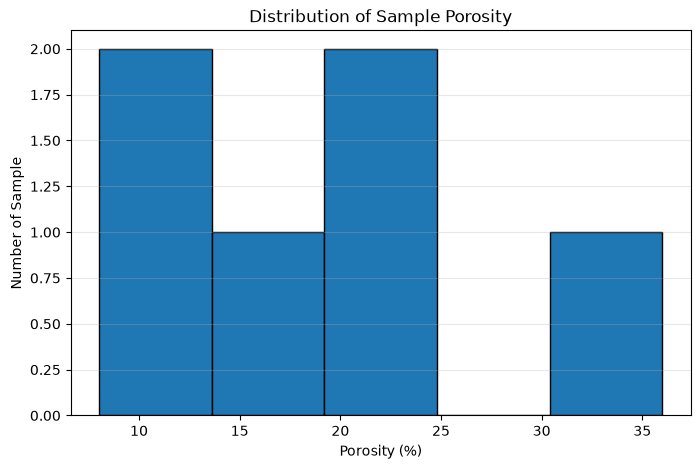

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Porosity"], bins=5, edgecolor="black")

plt.title("Distribution of Sample Porosity")
plt.xlabel("Porosity (%)")
plt.ylabel("Number of Sample")

plt.grid(axis="y", alpha=0.3)
plt.show()

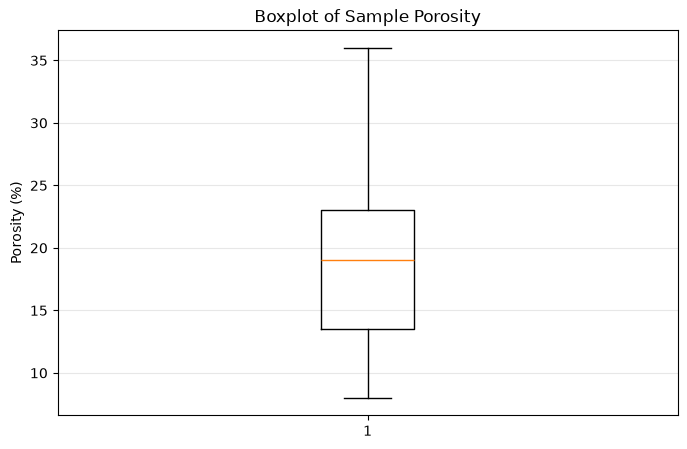

In [47]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))

plt.boxplot(df["Porosity"])
plt.title("Boxplot of Sample Porosity")
plt.ylabel("Porosity (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

<Figure size 800x500 with 0 Axes>

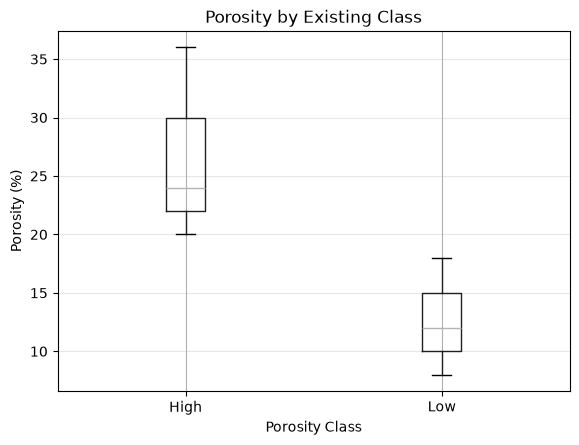

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df.boxplot(
    column="Porosity",
    by="prosity_Class"
)
plt.title("Porosity by Existing Class")
plt.suptitle("")
plt.xlabel("Porosity Class")
plt.ylabel("Porosity (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [52]:
# 1. Display the first rows
display(df.head())

# 2. Check the number of rows and columns 
print("Dataset shape:", df.shape)

# 3. Check data types
print("_nData types:")
print(df.dtypes)

# 4. Count missing values
print("_Missing values:")
print(df.isnull().sum())

# 5. Generate summary statistics
print("_nSummary statistics:")
display(df.describe())

,Sample,Porosity,prosity_Class,Porosity_Z_Score
0,A,8,Low,-1.299867
1,B,12,Low,-0.854199
2,C,20,High,0.037139
3,D,24,High,0.482808
4,E,36,High,1.819814


Dataset shape: (6, 4)
_nData types:
Sample                  str
Porosity              int64
prosity_Class           str
Porosity_Z_Score    float64
dtype: object
_Missing values:
Sample              0
Porosity            0
prosity_Class       0
Porosity_Z_Score    0
dtype: int64
_nSummary statistics:


,Porosity,Porosity_Z_Score
count,6.000000,6.000000e+00
mean,19.666667,-9.714451e-17
std,9.831921,1.095445e+00
min,8.000000,-1.299867e+00
25%,13.500000,-6.870728e-01
50%,19.000000,-7.427814e-02
75%,23.000000,3.713907e-01
max,36.000000,1.819814e+00


In [53]:
# Select the input feature
X = df[["Porosity_Z_Score"]]

# Select the target
y=df["Porosity"]
print("Feature (X):")
display(X.head())

print("Target (y):")
display(y.head())

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature (X):


,Porosity_Z_Score
0,-1.299867
1,-0.854199
2,0.037139
3,0.482808
4,1.819814


Target (y):


0     8
1    12
2    20
3    24
4    36
Name: Porosity, dtype: int64

Feature shape: (6, 1)
Target shape: (6,)


In [54]:
import pandas as pd

well_data ={
    "Sample": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "GR": [110, 95, 80, 70, 60, 55, 45, 40, 35, 30],
    "Resistivity": [2, 3, 4, 5, 8, 10, 15, 20, 25, 30],
    "Porosity": [8, 10, 13, 16, 19, 21, 24, 27, 30, 33]
}
well_df = pd.DataFrame(well_data)

display(well_df)

,Sample,GR,Resistivity,Porosity
0,A,110,2,8
1,B,95,3,10
2,C,80,4,13
3,D,70,5,16
4,E,60,8,19
5,F,55,10,21
6,G,45,15,24
7,H,40,20,27
8,I,35,25,30
9,J,30,30,33


In [57]:
# Input features
X = well_df[["GR", "Resistivity"]]

#Target to predict
y = well_df["Porosity"]

print("Features (X):")
display(X)
print("Target (y):")
display(y)

print("Feature shape:",X.shape)
print("Target shape:",y.shape)

Features (X):


,GR,Resistivity
0,110,2
1,95,3
2,80,4
3,70,5
4,60,8
5,55,10
6,45,15
7,40,20
8,35,25
9,30,30


Target (y):


0     8
1    10
2    13
3    16
4    19
5    21
6    24
7    27
8    30
9    33
Name: Porosity, dtype: int64

Feature shape: (10, 2)
Target shape: (10,)


In [58]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (8, 2)
Testing features: (2, 2)
Training targets: (8,)
Testing targets: (2,)


In [59]:
from sklearn.linear_model import LinearRegression

#Create the model
model = LinearRegression()

#Train the model using the training data
model.fit(X_train,y_train)

#Display the learned coefficients
print("GR coefficient:", model.coef_[0])
print("Resistivity coefficient:", model.coef_[1])
print("Intercept:",model.intercept_)

GR coefficient: -0.17148756010871855
Resistivity coefficient: 0.4089744929960274
Intercept: 25.82316276395569


In [60]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
import pandas as pd

# Predict porosity for the test samples
y_pred = model.predict(X_test)

#Compare actual and predicted values
results = pd.DataFrame({
    "Actual_Porosity": y_test,
    "Predicted_Porosity":y_pred
})
results["Prediction_Error"] =(
    results["Actual_Porosity"] - results["Predicted_Porosity"]
)
display(results.round(2))
#Evaluate the predictions
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

,Actual_Porosity,Predicted_Porosity,Prediction_Error
8,30,30.05,-0.05
1,10,10.76,-0.76


Mean Absolute Error (MAE): 0.4
Root Mean Squared Error (RMSE): 0.54


In [61]:
# Display actual and predicted values side by side
print("Actual values:")
print(y_test.to_list())

print("\nPredicted values:")
print(y_pred)

# Recalculate the errors
print("\nAbsolute errors:")
print(abs(y_test.to_numpy() - y_pred))

# Recalculate the metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\nCorrect MAE:", round(mae, 4))
print("Correct RMSE:", round(rmse, 4))

Actual values:
[30, 10]

Predicted values:
[30.04546049 10.75876803]

Absolute errors:
[0.04546049 0.75876803]

Correct MAE: 0.4021
Correct RMSE: 0.5375


In [63]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

#Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
#Train it using the same training data
rf_model.fit(X_train, y_train)
#Predict porosity for the same test samples
rf_pred = rf_model.predict(X_test)

#Evaluate the predictions
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest predictions:", np.round(rf_pred,2))
print("Random Forest MAE:", round(rf_mae, 4))
print("Random Forest RMSE:", round(rf_rmse, 4))

Random Forest predictions: [29.52 11.3 ]
Random Forest MAE: 0.89
Random Forest RMSE: 0.9799


In [72]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import numpy as np
#Use 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

model = {
    "Linear Regression": LinearRegression(),
    "Random Forest":RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}
for name, estimator in models.items():
    score = cross_val_score(
        estimator,
        X,
        y,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )
    mae_scores = -scores
    print(name)
    print("MAE in each fold:", np.round(mae_scores,2))
    print("Mean cross-validation MAE:", round(mae_scores,2))
    print("Mean cross-validation MAE:", round(mae_scores.mean(), 3))
    print()
    

NameError: name 'models' is not defined

In [73]:

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Define both models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

# Set up 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate each model
for name, estimator in models.items():
    scores = cross_val_score(
        estimator,
        X,
        y,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    mae_scores = -scores

    print(name)
    print("MAE in each fold:", np.round(mae_scores, 2))
    print("Mean cross-validation MAE:", round(mae_scores.mean(), 3))
    print()


Linear Regression
MAE in each fold: [0.4  0.93 0.48 0.2  0.24]
Mean cross-validation MAE: 0.45

Random Forest
MAE in each fold: [0.63 2.2  0.19 2.51 0.7 ]
Mean cross-validation MAE: 1.248



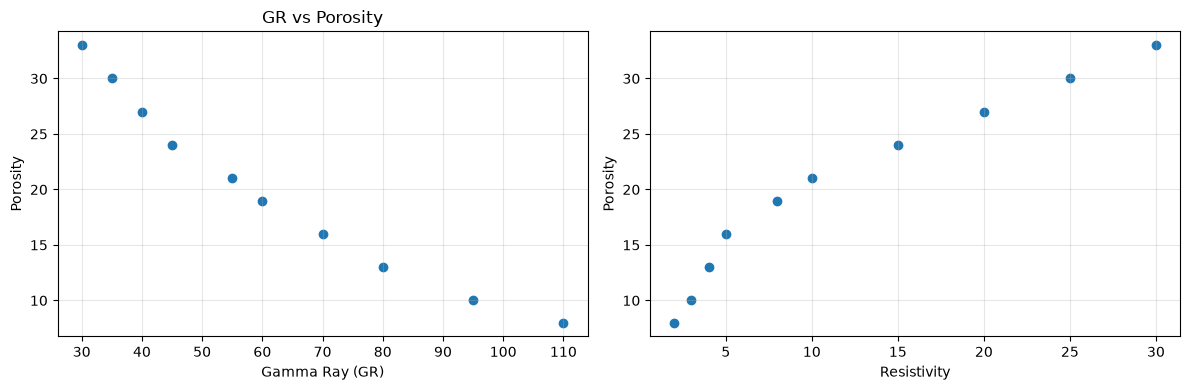

In [74]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Gamma ray versus porosity
axes[0].scatter(well_df["GR"],well_df["Porosity"])
axes[0].set_xlabel("Gamma Ray (GR)")
axes[0].set_ylabel("Porosity")
axes[0].set_title("GR vs Porosity")
axes[0].grid(alpha=0.3)

#Resistivity versus porosity
axes[1].scatter(well_df["Resistivity"], well_df["Porosity"])
axes[1].set_xlabel("Resistivity")
axes[1].set_ylabel("Porosity")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [76]:
#Calculate correlations between the variables
correlations = well_df[["GR", "Resistivity", "Porosity"]].corr()

print(correlations.round(3))

                GR  Resistivity  Porosity
GR           1.000       -0.892    -0.976
Resistivity -0.892        1.000     0.966
Porosity    -0.976        0.966     1.000


In [79]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
# Select the input features only
X_vif =well_df[["GR", "Resistivity"]].copy()

# Calculate VIF for each feature
vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values,i)
        for i in range(X_vif.shape[1])
    ]
})
print(vif_results.round(3))


       Feature   VIF
0           GR  1.39
1  Resistivity  1.39


In [83]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import pandas as pd
#Select the predictor variables
X_vif = well_df[["GR", "Resistivity"]]

# Add an intercept (constant)
X_vif_constant = add_constant(X_vif)

#Calculate VIF for each predictor
vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF":[
        variance_inflation_factor(
            X_vif_constant.values,
            i + 1
        )
        for i in range(len(X_vif.columns))
    ]
})
print(vif_results.round(3))

       Feature   VIF
0           GR  4.88
1  Resistivity  4.88


In [86]:
from sklearn.model_selection import KFold,cross_val_score
from sklearn.linear_model import LinearRegression
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=42)
feature_sets = {
    "GR only": ["GR"],
    "Resistivity only": ["Resistivity"],
    "GR + Resistivity": ["Resistivity"],
    "GR + Resistivity": ["GR", "Resistivity"]
}
for name,features in feature_sets.items():
    scores = cross_val_score(
        LinearRegression(),
        well_df[features],
        well_df["Porosity"],
        cv=cv,
        scoring ="neg_mean_absolute_error"
    )
    mae = -scores

    print(name)
    print("Fold MAEs:", np.round(mae, 3))
    print("Mean MAE:", round(mae.mean(), 3))
    print()
        

GR only
Fold MAEs: [1.012 3.151 0.89  2.616 1.887]
Mean MAE: 1.911

Resistivity only
Fold MAEs: [1.942 3.365 0.445 2.978 2.187]
Mean MAE: 2.183

GR + Resistivity
Fold MAEs: [0.402 0.934 0.476 0.196 0.242]
Mean MAE: 0.45



In [87]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

cv = KFold(n_splits=5, shuffle=True, random_state=42)
models= {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}
results =[]

for name, estimator in models.items():
    scores = cross_validate(
        estimator,
        well_df[["GR", "Resistivity"]],
        well_df["Porosity"],
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        }
    )
    results.append({
    "Model": name,
    "Mean_MAE": -scores["test_mae"].mean(),
    "Mean_RMSE": -scores["test_rmse"].mean()
})
results_df = pd.DataFrame(results)
print(results_df.round(3))

               Model  Mean_MAE  Mean_RMSE
0  Linear Regression     0.450      0.513
1      Random Forest     1.248      1.446


In [88]:
#Save the model comparison table
results_df.to_csv("model_comparison_results.csv", index=False)

print("Model comparison saved successfully.")
print(results_df.round(3))

Model comparison saved successfully.
               Model  Mean_MAE  Mean_RMSE
0  Linear Regression     0.450      0.513
1      Random Forest     1.248      1.446


In [91]:
results_df.to_csv("model_comparison_results.csv", index=False)

In [92]:
import os
print(os.getcwd())

C:\Users\owner


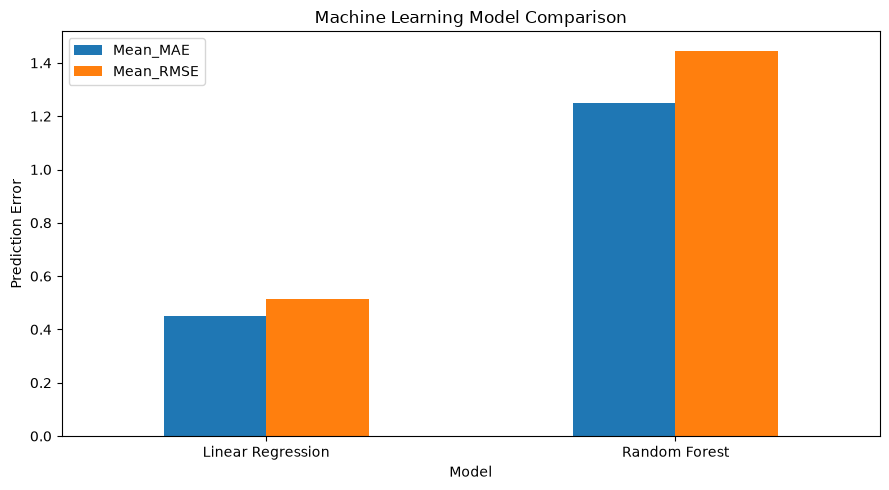

In [93]:
import matplotlib.pyplot as plt

ax = results_df.set_index("Model")[["Mean_MAE", "Mean_RMSE"]].plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Machine Learning Model Comparison")
ax.set_ylabel("Prediction Error")
ax.set_xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()